# 03 · Pre-freeze audits

**Phase:** audits (plan §7.2). **Looks at outcomes vs predictors?** No. Every table here is either outcome-only (episodes, lags, label counts) or feature-only (coverage, missingness). The numbers fill the blanks in `prereg/preregistration.md`.

Audit tables are written to `results/dev/audits/` as CSV (small, committed).

In [1]:
from flypredictor import load_config, Paths

cfg = load_config()
paths = Paths.from_root().ensure()
print("project root:", paths.root)
import copy
import pandas as pd
import matplotlib.pyplot as plt
from flypredictor.config import all_feature_vars
from flypredictor.data import episodes, states, labels, ert_jobs
from flypredictor.audit import coverage, maturity, realtime as art, definitions

out = paths.results / "dev" / "audits"
out.mkdir(parents=True, exist_ok=True)
eps = pd.read_parquet(paths.episodes_parquet)
panel = pd.read_parquet(paths.panel_parquet)
ert = episodes.load_ert(paths)

project root: C:\Users\markg\OneDrive\Desktop\DACCS\DACSS 756 - Machine Learning\DACSS_ML_FP


## A1 · Episode recount (plan finding C1)

Version 1 of the plan counted 110 episodes starting in a democracy, using the regime in the *start* year. ERT's own flag (`aut_ep_prch`, regime in the *pre-episode* year) gives the count below; the 9 version-1 "anomalies" were autocratic in the pre-episode year.

In [2]:
recount = maturity.episode_recount(eps)
recount.to_csv(out / "episode_recount.csv")
recount

outcome_label,averted regression,democratic breakdown,diminished democracy,outcome censored,preempted breakdown,total
decade,,,,,,
1910,0,1,0,0,0,1
1920,0,3,0,0,0,3
1930,1,7,0,0,0,8
1940,0,5,0,0,0,5
1950,0,1,0,0,0,1
1960,0,2,0,0,0,2
1970,0,3,0,0,1,4
1980,0,3,0,0,0,3
1990,0,13,0,0,0,13


## A2 · Label maturity: how long until an event is knowable? (plan §3.5)

* **start → confirmation**: years from an episode's start to the year its EDI decline reaches 0.10. Matters only if stage 1 predicts *onset*.
* **breakdown → genuine**: years from the RoW drop to ERT being able to code the breakdown (closed autocracy at once; otherwise a founding autocratic election or 5 years).

In [3]:
lag_c = maturity.lag_distribution(eps, "confirm_lag")
lag_b = maturity.lag_distribution(eps[eps["outcome"] == 1], "breakdown_confirm_lag")
buffers = maturity.maturity_report(eps)
lag_c.to_csv(out / "lag_start_to_confirmation.csv"); lag_b.to_csv(out / "lag_breakdown_to_genuine.csv")
display(lag_c.T, lag_b.T)
buffers

confirm_lag,0,1,2,3,4,5,6,7,8,9,10
episodes,24.000000,14.000000,15.000000,10.000000,10.000000,9.000000,5.000000,5.000000,6.000000,2.000000,1.0
cumulative_share,0.237624,0.376238,0.524752,0.623762,0.722772,0.811881,0.861386,0.910891,0.970297,0.990099,1.0


breakdown_confirm_lag,0,1,2,3,4,5
episodes,44.000000,6.000000,3.000000,2.000000,5.00000,11.0
cumulative_share,0.619718,0.704225,0.746479,0.774648,0.84507,1.0


{'onset_label_buffer': 7, 'breakdown_buffer': 5, 'confirmation_buffer': 0}

## A3 · Real-time states: ERT re-runs vs rule vs hindsight (plan §3.3)

Stage sizes under each state source, and agreement between the exact re-runs and the Python rule.

In [4]:
rt = ert_jobs.load_realtime(paths)
ev = episodes.country_events(eps, rt, ert)
st = {}
for src in ["ert_truncated", "rule", "hindsight"]:
    c = copy.deepcopy(cfg); c["labels"]["state_source"] = src
    st[src] = states.assign_states(ert, eps, c, rt if src == "ert_truncated" else None)
sizes = pd.DataFrame({s: d["stage"].value_counts().sort_index() for s, d in st.items()})
sizes.to_csv(out / "stage_sizes_by_source.csv")
cmp = art.compare_states(st["ert_truncated"], st["rule"], "ert", "rule")
print(f"agreement (democracy rows): {cmp['agreement']:.4f}")
display(sizes, cmp["crosstab"])

agreement (democracy rows): 0.9958


,ert_truncated,rule,hindsight
stage,,,
0,14678,14678,14678
1,5031,5051,4786
2,148,128,393


stage_rule,1,2
stage_ert,,
1,5030,1
2,21,127


In [5]:
# Example: who was 'in an episode' in 2010, in real time vs in the final coding?
names = ert[["country_id", "country_text_id"]].drop_duplicates()
y2010 = (st["ert_truncated"].query("year == 2010")[["country_id", "stage"]]
         .merge(st["hindsight"].query("year == 2010")[["country_id", "stage"]], on="country_id", suffixes=("_realtime", "_hindsight"))
         .merge(names, on="country_id"))
y2010[y2010["stage_realtime"] != y2010["stage_hindsight"]]

,country_id,stage_realtime,stage_hindsight,country_text_id
19,25,1,2,BOL
22,28,1,2,MLI
31,39,1,2,IND
34,42,1,2,KOR
48,56,1,2,IDN
80,88,1,2,MDV
136,150,2,1,BIH
156,176,1,2,MKD
168,198,1,2,SRB
176,210,1,2,HUN


## A4 · Breakdowns vs confirmation timing

How many breakdowns happen *before* the episode could be confirmed in real time? Those breakdowns can never be forecast by a stage-2 (in-episode) model.

In [6]:
b = eps[eps["outcome"] == 1]
timing = pd.Series({
    "breakdown episodes": len(b),
    "breakdown in the episode's first year": int((b["breakdown_year"] == b["start_year"]).sum()),
    "breakdown at or before rule confirmation": int((b["breakdown_year"] <= b["confirm_year_rule"]).sum()),
    "breakdown after confirmation (stage-2 forecastable)": int((b["breakdown_year"] > b["confirm_year_rule"]).sum()),
})
timing.to_csv(out / "breakdown_timing.csv")
timing

breakdown episodes                                     71
breakdown in the episode's first year                  23
breakdown at or before rule confirmation               51
breakdown after confirmation (stage-2 forecastable)    20
dtype: int64

## A5 · Event counts per period (inputs to the power simulation)

Observable label rows, positives and base rates by stage, event, horizon and period (development = origins ≤ 2004; locked = 2005–2024).

In [7]:
lab = pd.read_parquet(paths.labels_parquet)
summ = labels.label_summary(lab, cfg)
summ.to_csv(out / "label_counts.csv", index=False)
summ.query("period != 'after_locked'").pivot_table(
    index=["stage", "event", "k"], columns="period", values=["rows", "positives"], aggfunc="sum")

positives               rows       
period                 development locked development locked
stage event         k                                       
1     breakdown     1           35     13        3255   1323
                    2           72     26        3255   1236
                    3          109     38        3255   1151
                    5          181     56        3255    980
                    10         341     63        3243    538
      declaration   1           36     53        3255   1707
                    2           77    100        3255   1634
                    3          118    143        3255   1561
                    5          200    207        3255   1405
                    10         386    254        3243    980
      row_breakdown 1           42     26        3255   1707
                    2           85     54        3255   1634
                    3          129     81        3255   1561
                    5          215    120        3255   1405
                    10         382    149        3243    980
2     breakdown     1            6      7          21     53
                    2           10     12          21     48
                    3           14     14          21     40

## A6 · Coverage of every configured indicator (feature-only)

In [8]:
vars_ = all_feature_vars(cfg)
cov = coverage.coverage_table(panel, vars_)
cov.to_csv(out / "coverage.csv", index=False)
cov.round(3)

,variable,first_year,last_year,share_all,share_democracy,share_dem_1900-1944,share_dem_1945-1989,share_dem_1990-
0,v2cacamps,1900,2025,0.974,0.981,0.932,0.969,0.996
1,v2caviol,1900,2025,0.975,0.985,0.932,0.976,0.999
2,v2clkill,1900,2025,1.000,1.000,1.000,1.000,1.000
3,v2x_jucon,1900,2025,0.988,1.000,1.000,1.000,1.000
4,v2juhcind,1900,2025,0.990,1.000,1.000,1.000,1.000
5,v2juncind,1900,2025,1.000,1.000,1.000,1.000,1.000
6,v2juhccomp,1900,2025,0.985,1.000,1.000,1.000,1.000
7,v2jureview,1900,2025,0.995,1.000,1.000,1.000,1.000
8,v2exrescon,1900,2025,0.993,1.000,1.000,1.000,1.000
9,v2xlg_legcon,1900,2025,0.859,1.000,0.998,1.000,1.000


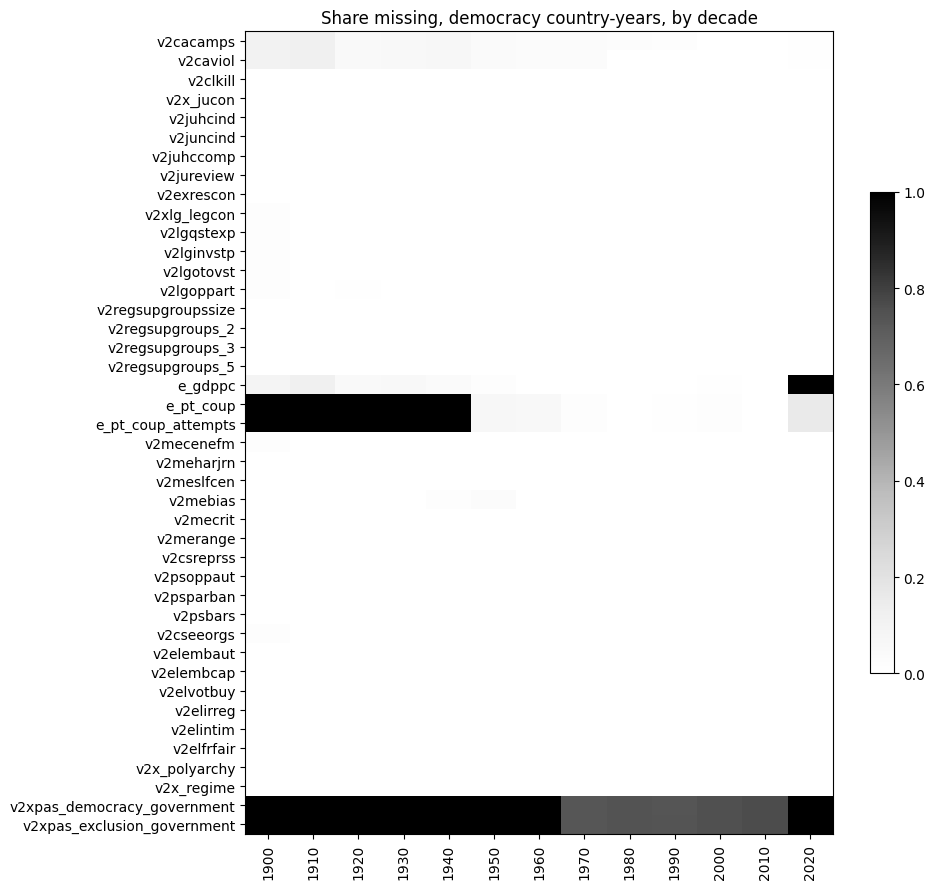

In [9]:
miss = coverage.missingness_by_decade(panel, vars_)
miss.to_csv(out / "missing_by_decade.csv")
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(miss.values, aspect="auto", cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(miss.shape[1]), [str(c) for c in miss.columns], rotation=90)
ax.set_yticks(range(miss.shape[0]), miss.index)
ax.set_title("Share missing, democracy country-years, by decade")
fig.colorbar(im, ax=ax, shrink=0.6)
fig.tight_layout(); fig.savefig(paths.figures / "audit_missing_by_decade.png", dpi=150)

## A7 · Era-proxy check (plan §4.2)

A missingness flag that mostly encodes *when* a row is would let a model learn "recent years" (which also have the highest base rate). Flagged variables get a coverage rule (`config/features.yaml → coverage_rules`) instead of a missingness indicator.

In [10]:
flags = coverage.era_proxy_flags(panel, vars_)
flags.to_csv(out / "era_proxy_flags.csv", index=False)
flags.round(3).query("era_proxy")

,variable,share_missing,corr_missing_year,share_missing_last6y,era_proxy,reason
19,e_pt_coup,0.164,-0.682,0.156,True,corr
20,e_pt_coup_attempts,0.164,-0.682,0.156,True,corr
18,e_gdppc,0.112,0.317,1.000,True,corr+ends_early
41,v2xpas_exclusion_government,0.837,-0.165,1.000,True,ends_early
40,v2xpas_democracy_government,0.837,-0.165,1.000,True,ends_early


## A7b · Development vs locked-window coverage (review finding, D-16)

A series that stops before the last locked origin gives the model a feature it never saw in training (GDP ends 2019, so "years since observed" is ~0 in training and 1–5 in 2020–2024). `locked_gap` flags it.

In [11]:
win = coverage.window_coverage(panel, vars_, cfg)
win.to_csv(out / "window_coverage.csv", index=False)
win.round(3).query("locked_gap")

,variable,last_year_democracy_rows,missing_dev,missing_locked,locked_minus_dev,locked_gap
0,e_gdppc,2019,0.015,0.245,0.230,True
1,v2xpas_democracy_government,2019,0.845,0.816,-0.028,True
2,v2xpas_exclusion_government,2019,0.845,0.816,-0.029,True


## A8 · Risk-set definition: RoW vs ERT regime type (review finding, D-15)

Stages use RoW (`v2x_regime ≥ 2`); ERT decides whether an episode starts in a democracy with its own `reg_type`. With `democracy.require_ert_democracy: true` the risk sets are RoW democracies that ERT also treats as democracies. The second table lists every RoW democracy → autocracy change that ERT does **not** count as a democratic breakdown (`reverts` = back to democracy within 2 years). These feed the `row_breakdown` sensitivity outcome.

In [12]:
xt = definitions.risk_set_vs_ert(st["ert_truncated"], ert)
display(xt)
trans = definitions.row_transitions(ert, eps)
trans.to_csv(out / "row_transitions.csv", index=False)
print(f"RoW democracy->autocracy changes: {len(trans)}; ERT breakdowns: {int(trans.ert_breakdown.sum())}; "
      f"not counted and lasting: {int((~trans.ert_breakdown & ~trans.reverts).sum())}; "
      f"not counted and reverting: {int((~trans.ert_breakdown & trans.reverts).sum())}")
trans[~trans.ert_breakdown & ~trans.reverts]

ERT reg_type,-1.0,0.0,1.0
RoW democracy,,,
False,66,14551,16
True,0,45,5179


RoW democracy->autocracy changes: 104; ERT breakdowns: 71; not counted and lasting: 22; not counted and reverting: 11


,country_id,country_text_id,year,v2x_regime,v2x_polyarchy,reg_type_prev,aut_ep_outcome,ert_breakdown,reverts
4,7,GHA,1981,0.0,0.252,0.0,5,False,False
5,12,ALB,2025,1.0,0.484,1.0,0,False,False
12,28,MLI,2018,1.0,0.518,0.0,5,False,False
15,37,ARG,1976,1.0,0.133,0.0,5,False,False
18,40,KEN,2007,1.0,0.511,0.0,0,False,False
19,40,KEN,2017,1.0,0.512,1.0,0,False,False
20,45,NGA,2021,1.0,0.488,1.0,0,False,False
28,56,IDN,1958,1.0,0.459,0.0,5,False,False
36,61,ZMB,2025,1.0,0.497,0.0,0,False,False
49,95,SLE,2023,1.0,0.512,1.0,0,False,False


## A9 · When is a slide first recognised? (review finding, D-07)

For each real-time declaration: is the country still a democracy in the declaration year? A declaration in a year that is already autocratic means the episode was first recognised at or after breakdown (mostly coups), so the stage-1 "confirmation" event and the breakdown event coincide.

In [13]:
dt = definitions.declaration_timing(ev, st["ert_truncated"], cfg["splits"]["dev_last_origin"])
dt.to_csv(out / "declaration_timing.csv", index=False)
pd.crosstab(dt["period"], dt["still_democracy"], margins=True)

still_democracy,False,True,All
period,,,
development,35,7,42
later,19,40,59
All,54,47,101


## Findings to carry into the pre-registration

From the run of 2026-10-09 with the review fixes (`require_ert_democracy: true`, `row_breakdown` sensitivity):

* Democratic episodes: 101 (71 breakdown, 13 averted, 1 preempted, 1 diminished, 15 censored). Every episode is declared exactly once in the real-time re-runs; no declaration is later withdrawn.
* Buffers: stage 1 (confirmation) = 0; onset-label buffer would be 7; stage-2 breakdown buffer = 5.
* Real-time vs rule agreement: 99.6% of democracy rows; stage-2 size in real time: 148 country-years.
* Breakdowns forecastable from inside an episode: 20 of 71 (51 at or before real-time confirmation; 23 in the episode's first year).
* Declarations made while the country is still a democracy: 47 of 101 (the other 54 come at or after breakdown). Stage-1 k = 1 positives that are declarations while democratic: development 7 of 36, locked 40 of 53.
* Risk set: 45 RoW-democracy rows that ERT treats as autocracies are removed (stage 1: 5,076 → 5,031).
* Locked-window events (k = 1): stage-1 declarations 53, stage-1 ERT breakdowns 13, stage-1 RoW breakdowns 26, stage-2 breakdowns 7.
* Era-proxy variables: e_pt_coup, e_pt_coup_attempts (corr); e_gdppc (corr + ends early); v2xpas_* (ends early). Locked-window gaps: e_gdppc, v2xpas_*.